# 06 Delay Lines

**Series:** Physics of the CHARA Array (Mount Wilson Observatory)
**Topic T6:** how CHARA keeps the light paths from different telescopes equal to within microns while the star moves across the sky.

Notebook 02 showed that fringes only appear when the two light paths match to within a few micrometres. Starlight reaches one telescope before the other, by up to hundreds of metres of extra travel. Notebook 05 gave the geometry of that head start. This notebook covers:

1. How large the delay is and how fast it changes.
2. The hardware: fixed delays plus mirrors on moving carts.
3. A check against the cart positions CHARA actually recorded.
4. Why micron accuracy needs a fringe tracker.
5. Why the air in the delay lines smears the fringes, and how glass fixes it.

Hardware numbers come from *CHARA Array Delay Lines: Upgrades, Performance and Future Directions* (arXiv:2602.16009) and ten Brummelaar et al. (2005, ApJ 628, 453).

In [1]:
%matplotlib inline
import itertools
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.coordinates import SkyCoord, FK5
from astropy.time import Time
from ipywidgets import interact, FloatSlider, Dropdown, IntSlider

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

# Telescope positions in metres (east, north, up) relative to S1, ten Brummelaar et al. (2005)
STATIONS = {
    "S1": (0.000, 0.000, 0.000),
    "S2": (-5.748, 33.581, 0.637),
    "E1": (125.333, 305.928, -5.919),
    "E2": (70.389, 269.715, -2.803),
    "W1": (-175.068, 216.327, -10.798),
    "W2": (-69.085, 199.342, 0.471),
}
PAIRS = [f"{a}-{b}" for a, b in itertools.combinations(STATIONS, 2)]
LATITUDE = np.radians(34.2244)
MIN_ALTITUDE_DEG = 30

CART_RANGE = 92.0                             # optical delay from one cart, metres (46 m rail, light passes twice)
POPS = [0.0, 36.6, 73.2, 109.7, 143.1]        # fixed "Pipes of Pan" delays, metres


def baseline_vector(t1, t2):
    return np.subtract(STATIONS[t2], STATIONS[t1])


def project(enu, hour_angle, dec):
    # Same geometry as notebook 05: projected baseline (u, v) and delay w, in metres
    e, n, up = enu
    x = -np.sin(LATITUDE) * n + np.cos(LATITUDE) * up
    z = np.cos(LATITUDE) * n + np.sin(LATITUDE) * up
    u = np.sin(hour_angle) * x + np.cos(hour_angle) * e
    v = (-np.sin(dec) * np.cos(hour_angle) * x + np.sin(dec) * np.sin(hour_angle) * e
         + np.cos(dec) * z)
    w = (np.cos(dec) * np.cos(hour_angle) * x - np.cos(dec) * np.sin(hour_angle) * e
         + np.sin(dec) * z)
    return u, v, w


def altitude_deg(hour_angle, dec):
    s = (np.sin(LATITUDE) * np.sin(dec)
         + np.cos(LATITUDE) * np.cos(dec) * np.cos(hour_angle))
    return np.degrees(np.arcsin(s))

## 1. The delay is the third coordinate, w

In notebook 05 the function `project` returned three numbers. $u$ and $v$ are the baseline as seen from the star. The third, $w$, is the part of the baseline that points **at** the star. That is exactly the extra distance the starlight travels to reach the farther telescope, the geometric delay $B \sin\theta$ from notebook 02.

As Earth turns, $w$ changes. The delay line must add $w$ of extra path to the beam from the telescope the light reaches first, and follow it as it changes.

Choose a baseline and a star. The thick part of each curve is when the star is above 30° altitude.

In [2]:
@interact(
    pair=Dropdown(options=PAIRS, value="E1-W1", description="Baseline"),
    dec_deg=FloatSlider(value=40, min=-25, max=85, step=1, description="dec (°)",
                        continuous_update=False, style=SLIDER_STYLE),
)
def show_delay(pair, dec_deg):
    a, b = pair.split("-")
    dec = np.radians(dec_deg)
    hours = np.linspace(-6, 6, 1201)
    ha = np.radians(15 * hours)
    _, _, w = project(baseline_vector(a, b), ha, dec)
    rate = np.gradient(w, hours * 3600) * 1000  # mm/s
    up = altitude_deg(ha, dec) >= MIN_ALTITUDE_DEG

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
    for ax, y, label in [(ax1, w, "Delay to add (m)"), (ax2, rate, "Rate of change (mm/s)")]:
        ax.plot(hours, y, color=GREY, lw=1)
        ax.plot(hours, np.where(up, y, np.nan), color=BLUE, lw=3)
        ax.axhline(0, color="black", lw=0.6)
        ax.set_xlabel("Hour angle (h, 0 = star at its highest)")
        ax.set_ylabel(label)
    ax1.set_title(f"{pair}: geometric delay, dec {dec_deg:.0f}°", fontsize=10)
    ax2.set_title("How fast the delay changes", fontsize=10)
    plt.tight_layout()
    plt.show()

    if not up.any():
        print("The star never rises above 30° from Mount Wilson.")
        return
    print(f"Baseline length {np.hypot(*baseline_vector(a, b)[:2]):.0f} m. While observable:")
    print(f"  delay ranges from {w[up].min():.1f} to {w[up].max():.1f} m (a swing of {np.ptp(w[up]):.1f} m)")
    print(f"  fastest change {np.abs(rate[up]).max():.1f} mm/s of optical path, "
          f"so a cart moves at up to {np.abs(rate[up]).max() / 2:.1f} mm/s")

interactive(children=(Dropdown(description='Baseline', index=10, options=('S1-S2', 'S1-E1', 'S1-E2', 'S1-W1', …

A negative delay means the light reaches the other telescope of the pair first. The delay is always added to whichever beam is ahead.

**Try this:**

- E1-W1 at dec 40°: the delay swings through about 450 m during the night, changing by up to about 17 mm every second.
- S1-S2 (34 m): the delay never exceeds about 20 m and changes slowly.
- Dec 70°: a star near the pole moves slowly across the sky, so the delay changes more gently.

The last printed line divides the rate by two. The reason is in the next section.

## 2. The hardware: fixed pipes plus moving carts

Light from each telescope travels through vacuum pipes to the central beam-combining lab. On the way it passes two kinds of delay.

- **Pipes of Pan (PoP).** Fixed extra paths of 0, 36.6, 73.2, 109.7 or 143.1 m, chosen before observing by moving a mirror. They are in vacuum.
- **Moving carts.** Each of the six beams has a cart rolling on a 46 m rail. The cart carries a **cat's eye**, a mirror arrangement that sends the light back along the direction it came from. The light goes out to the cart and back, so moving the cart by 1 m adds 2 m of path. That gives 92 m of continuously adjustable delay.

Each cart's position is measured by a laser (1.319 µm wavelength) and held to about 12 nm rms, with speeds up to about 8 mm/s. The upgraded carts reach 20 mm/s.

The drawing shows why the path changes by twice the cart's movement.

In [3]:
@interact(cart=FloatSlider(value=20, min=0, max=46, step=1, description="cart (m)",
                            continuous_update=False, style=SLIDER_STYLE))
def show_cart(cart):
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot([0, 50], [-0.9, -0.9], color=GREY, lw=4, solid_capstyle="butt")
    ax.text(25, -1.35, "46 m rail", ha="center", fontsize=9, color=GREY)
    x = 2 + cart
    ax.add_patch(plt.Rectangle((x, -0.75), 2, 1.5, color=BLUE, alpha=0.25))
    ax.plot([x + 2, x + 2.6, x + 2], [0.75, 0, -0.75], color=BLUE, lw=2)
    ax.text(x + 1, 1.0, "cat's eye on cart", ha="center", fontsize=9, color=BLUE)
    ax.annotate("", xy=(x + 2, 0.35), xytext=(-2, 0.35),
                arrowprops=dict(arrowstyle="->", color=ORANGE, lw=2))
    ax.annotate("", xy=(-2, -0.35), xytext=(x + 2, -0.35),
                arrowprops=dict(arrowstyle="->", color=ORANGE, lw=2))
    ax.text(-2.5, 0.35, "light in", ha="right", va="center", fontsize=9)
    ax.text(-2.5, -0.35, "light out", ha="right", va="center", fontsize=9)
    ax.set_xlim(-10, 54)
    ax.set_ylim(-1.6, 1.4)
    ax.axis("off")
    ax.set_title(f"Cart at {cart:.0f} m adds {2 * cart:.0f} m of optical path", fontsize=10)
    plt.show()

interactive(children=(FloatSlider(value=20.0, continuous_update=False, description='cart (m)', max=46.0, step=…

### Choosing the fixed delay

A PoP is chosen at the start, then the cart covers a 92 m window above it. If the delay needed during the night swings by more than 92 m, the star leaves the window and observing must stop or the PoP must be changed.

The plot below simplifies by assuming the pipes from both telescopes to the lab have equal length. In reality they differ by up to about 27 m (section 3). That shifts every curve by a fixed amount, which is one reason CHARA can choose a PoP for either telescope.

In [4]:
@interact(
    pair=Dropdown(options=PAIRS, value="E1-W1", description="Baseline"),
    dec_deg=FloatSlider(value=40, min=-25, max=85, step=1, description="dec (°)",
                        continuous_update=False, style=SLIDER_STYLE),
    pop=Dropdown(options=[(f"{p:.1f} m", p) for p in POPS], value=73.2, description="PoP"),
)
def show_window(pair, dec_deg, pop):
    a, b = pair.split("-")
    dec = np.radians(dec_deg)
    hours = np.linspace(-6, 6, 1201)
    ha = np.radians(15 * hours)
    _, _, w = project(baseline_vector(a, b), ha, dec)
    need = np.abs(w)
    up = altitude_deg(ha, dec) >= MIN_ALTITUDE_DEG
    inside = up & (need >= pop) & (need <= pop + CART_RANGE)

    fig, ax = plt.subplots(figsize=(10, 4.4))
    ax.axhspan(pop, pop + CART_RANGE, color=AQUA, alpha=0.15, label="reach of the cart with this PoP")
    ax.plot(hours, np.where(up, need, np.nan), color=GREY, lw=2, label="delay needed, star above 30°")
    ax.plot(hours, np.where(inside, need, np.nan), color=BLUE, lw=4, label="observable")
    ax.set_xlabel("Hour angle (h)")
    ax.set_ylabel("Delay needed (m)")
    ax.set_ylim(0, 340)
    ax.set_title(f"{pair}, dec {dec_deg:.0f}°, PoP {pop:.1f} m", fontsize=10)
    ax.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()

    step = hours[1] - hours[0]
    print(f"Star above 30° for {up.sum() * step:.1f} h. Delay within reach for {inside.sum() * step:.1f} h of that.")
    for p in POPS:
        hrs = (up & (need >= p) & (need <= p + CART_RANGE)).sum() * step
        print(f"  PoP {p:6.1f} m -> {hrs:4.1f} h")

interactive(children=(Dropdown(description='Baseline', index=10, options=('S1-S2', 'S1-E1', 'S1-E2', 'S1-W1', …

**Try this:**

- E1-W1 at dec 40°: no single PoP covers the whole night. Each one gives a few hours.
- S1-S2: the first PoP (0 m) covers everything.
- Change the declination and watch which PoP is best change.

With six telescopes, five delay lines move relative to one reference. Each beam gets its own PoP, chosen so that all five delays stay within reach together.

## 3. Checking against CHARA's own records

Every MIRC-X data file records, for each telescope, the cart position, the PoP path and the fixed internal paths (light pipe, air path and beam path). If the geometry is right, then for every telescope at the same moment:

$$w_\text{telescope} - (2 \times \text{cart} + \text{PoP path} + \text{light pipe} + \text{air path} + \text{beam path}) = \text{the same number}$$

where $w_\text{telescope}$ is the delay of that telescope relative to S1. The files are the CL Lac observations used in notebooks 07 and 08 (MIRC-X, July 2019, Chiavassa et al. 2020).

Two details matter at this precision:

- The star's position must be precessed to the date of observation. Using the year-2000 coordinates leaves errors of about 40 cm.
- In these files W1 repeats its light-pipe value as its beam path, and W2 records no PoP path. Those two telescopes are left out.

This cell downloads about 4 MB of public data the first time it runs.

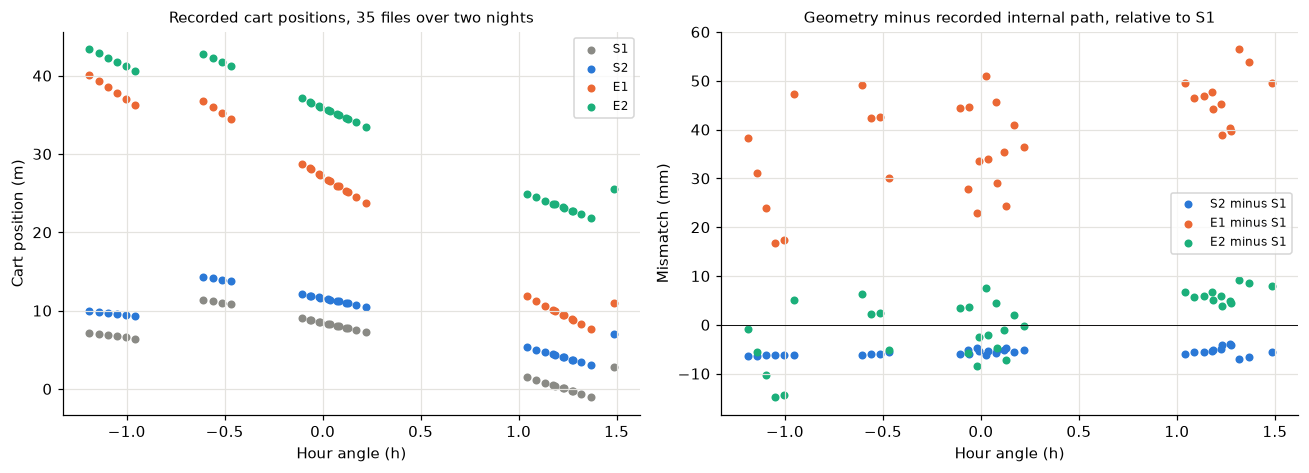

1 file set aside: its S1 record disagrees with every other telescope by over 0.5 m.
S2: delay relative to S1 up to 13 m, mismatch from -7 to -4 mm
E1: delay relative to S1 up to 119 m, mismatch from +17 to +56 mm
E2: delay relative to S1 up to 99 m, mismatch from -15 to +9 mm


In [5]:
import csv
import io
import urllib.parse
import urllib.request
from concurrent.futures import ThreadPoolExecutor

TAP_URL = "https://tap.jmmc.fr/vollt/tap/sync"
OIDB_URL = "https://oidb.jmmc.fr"
CL_LAC_DIR = Path("data/irc_50448")


def download_cl_lac():
    # Public MIRC-X data on CL Lac (IRC+50448) from the JMMC Optical Interferometry Database
    done_marker = CL_LAC_DIR / ".complete"
    if done_marker.exists():
        return sorted(CL_LAC_DIR.glob("*.fits"))
    CL_LAC_DIR.mkdir(parents=True, exist_ok=True)
    query = ("SELECT access_url FROM oidb WHERE facility_name = 'CHARA' AND data_rights = 'public' "
             "AND calib_level = 3 AND target_name = 'IRC+50448'")
    params = urllib.parse.urlencode({"REQUEST": "doQuery", "LANG": "ADQL",
                                     "FORMAT": "csv", "QUERY": query}).encode()
    with urllib.request.urlopen(TAP_URL, data=params, timeout=60) as response:
        rows = list(csv.DictReader(io.StringIO(response.read().decode())))

    def fetch(row):
        url = urllib.parse.urljoin(OIDB_URL, row["access_url"])
        target = CL_LAC_DIR / Path(urllib.parse.urlparse(url).path).name
        if not target.exists():
            urllib.request.urlretrieve(url, target)

    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(fetch, rows))
    done_marker.touch()
    return sorted(CL_LAC_DIR.glob("*.fits"))


def hours(text):
    sign = -1 if text.strip().startswith("-") else 1
    h, m, s = (abs(float(part)) for part in text.split(":"))
    return sign * (h + m / 60 + s / 3600)


CHECKED = ["S1", "S2", "E1", "E2"]
star = SkyCoord("22h51m35.2533s +52d20m21.488s")  # CL Lac, year-2000 position
records = []
for path in download_cl_lac():
    header = fits.getheader(path)
    of_date = star.transform_to(FK5(equinox=Time(header["MJD-OBS"], format="mjd")))
    ha = np.radians(15 * hours(header["HA"]))
    row = {"HA": hours(header["HA"])}
    for t in CHECKED:
        enu = [header[f"CHARA {t}_BASELINE_{axis}"] for axis in "XYZ"]
        _, _, w = project(enu, ha, of_date.dec.radian)
        internal = (2 * header[f"CHARA CARTPOS{t}"] + header[f"CHARA {t}_POPPATH"]
                    + header[f"CHARA {t}_LIGHTPIPE"] + header[f"CHARA {t}_AIRPATH"]
                    + header[f"CHARA {t}_BEAMPATH"])
        row[t] = w - internal
        row[t + " w"] = w
        row[t + " cart"] = header[f"CHARA CARTPOS{t}"]
    records.append(row)

# One file records S1 about 1.5 m away from the others, as if logged mid-move. Set it aside.
outliers = [r for r in records if any(abs(r[t] - r["S1"]) > 0.5 for t in CHECKED[1:])]
records = [r for r in records if r not in outliers]
ha_obs = np.array([r["HA"] for r in records])
offsets = {t: np.array([r[t] - r["S1"] for r in records]) for t in CHECKED[1:]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
for t, colour in zip(CHECKED, [GREY, BLUE, ORANGE, AQUA]):
    ax1.scatter(ha_obs, [r[t + " cart"] for r in records], s=18, color=colour, label=t)
ax1.set_xlabel("Hour angle (h)")
ax1.set_ylabel("Cart position (m)")
ax1.set_title(f"Recorded cart positions, {len(records)} files over two nights", fontsize=10)
ax1.legend(fontsize=8)
for t, colour in zip(CHECKED[1:], [BLUE, ORANGE, AQUA]):
    ax2.scatter(ha_obs, 1000 * offsets[t], s=18, color=colour, label=f"{t} minus S1")
ax2.axhline(0, color="black", lw=0.6)
ax2.set_xlabel("Hour angle (h)")
ax2.set_ylabel("Mismatch (mm)")
ax2.set_title("Geometry minus recorded internal path, relative to S1", fontsize=10)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{len(outliers)} file set aside: its S1 record disagrees with every other telescope by over 0.5 m.")
for t in CHECKED[1:]:
    print(f"{t}: delay relative to S1 up to {max(abs(r[t + ' w']) for r in records):.0f} m, "
          f"mismatch from {1000 * offsets[t].min():+.0f} to {1000 * offsets[t].max():+.0f} mm")

The carts move by metres between files, and the geometry from notebook 05 predicts where they had to be to within about 6 cm, over delays of up to about 120 m. One file was set aside because its S1 record disagrees with all the other telescopes at once, which points to a logging glitch rather than a geometry error.

A few centimetres is still thousands of times too coarse for fringes. The remaining error is found by searching for the fringes and then tracking them, the subject of the next section.

## 4. Why the carts need a fringe tracker

The fringe packet from notebook 02 is only about $\lambda^2 / \Delta\lambda$ wide, the **coherence length**. Outside it the fringes vanish.

- Across the full H band (1.5–1.8 µm), it is about 9 µm.
- MIRC-X spreads the light into a spectrum. Each narrow channel (resolving power $R = \lambda / \Delta\lambda \approx 50$) has a coherence length of $R\lambda \approx 80$ µm. That makes the fringes easier to find.

The delay model uses the telescope positions. If a position is wrong by even a millimetre, the predicted delay is wrong by up to a millimetre, and the error changes through the night as the baseline turns. Below, a position error is added to one telescope of S1-E1. The plot shows how far the fringe packet drifts from where the carts put it.

A **fringe tracker** solves this. It measures where the packet is, many times a second, and nudges a cart to recentre it. For the CL Lac data, MIRC-X itself did this job.

In [6]:
BANDS = {
    "Full H band, R ≈ 5.5": 1.65 / 0.30,
    "MIRC-X prism, R ≈ 50": 50,
    "Higher resolution, R ≈ 190": 190,
}


@interact(
    east_mm=FloatSlider(value=0.2, min=-2, max=2, step=0.1, description="east (mm)",
                        continuous_update=False, style=SLIDER_STYLE),
    north_mm=FloatSlider(value=0.1, min=-2, max=2, step=0.1, description="north (mm)",
                         continuous_update=False, style=SLIDER_STYLE),
    up_mm=FloatSlider(value=0.0, min=-2, max=2, step=0.1, description="up (mm)",
                      continuous_update=False, style=SLIDER_STYLE),
    band=Dropdown(options=list(BANDS), value="MIRC-X prism, R ≈ 50", description="Spectrum",
                  layout={"width": "340px"}),
)
def show_drift(east_mm, north_mm, up_mm, band):
    dec = np.radians(40)
    hrs = np.linspace(-4, 4, 801)
    _, _, error = project(np.array([east_mm, north_mm, up_mm]) * 1e-3, np.radians(15 * hrs), dec)
    error_um = error * 1e6
    error_um -= error_um[len(hrs) // 2]  # assume fringes were found at transit
    coherence_um = BANDS[band] * 1.65
    contrast = np.abs(np.sinc(error_um / coherence_um))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    ax1.axhspan(-coherence_um / 2, coherence_um / 2, color=AQUA, alpha=0.15,
                label=f"inside the packet (±{coherence_um / 2:.0f} µm)")
    ax1.plot(hrs, error_um, color=BLUE)
    ax1.set_xlabel("Hour angle (h)")
    ax1.set_ylabel("Fringe packet offset (µm)")
    ax1.set_title("Drift without a fringe tracker (found at hour angle 0)", fontsize=10)
    ax1.legend(fontsize=8, loc="upper left")
    ax2.plot(hrs, contrast, color=ORANGE)
    ax2.set_ylim(0, 1.05)
    ax2.set_xlabel("Hour angle (h)")
    ax2.set_ylabel("Fringe contrast kept")
    ax2.set_title(band, fontsize=10)
    plt.tight_layout()
    plt.show()
    lost = hrs[contrast < 0.5]
    print("Contrast stays above half all night." if len(lost) == 0 else
          f"Contrast drops below half {np.abs(lost).min():.1f} h from hour angle 0.")

interactive(children=(FloatSlider(value=0.2, continuous_update=False, description='east (mm)', max=2.0, min=-2…

**Try this:**

- With the defaults (0.2 mm east and 0.1 mm north), the packet drifts out of reach about an hour after the fringes were found, and by over 100 µm after four hours.
- Switch to the full H band. The narrower packet is lost much sooner.
- Set all errors to 0. In practice the atmosphere still moves the packet by several microns many times a second (notebook 07), so a fringe tracker is needed anyway.

## 5. Air in the delay lines spreads the colours apart

The carts run in air, not vacuum. Air slows light slightly, and slows blue light more than red. Its refractive index is about $n \approx 1.00027$ in the H band, with a small change across the band. If one beam travels an extra length $L$ of air, each wavelength is delayed by a slightly different amount, $(n(\lambda) - 1) L$.

- A delay that is the **same** for every wavelength just moves the fringe packet. The carts absorb it.
- The **difference** between wavelengths cannot be undone by moving a cart. The fringes from different colours no longer line up, and the packet smears and loses contrast.

CHARA fixes this with **longitudinal dispersion compensators**: wedges of glass slid into the beam with less air path. Glass has its own spread between colours, which cancels most of the air's.

Below, the refractive index of air uses Ciddor's (1996) formula, scaled to Mount Wilson's pressure (about 820 hPa) and 10 °C. The glass is Schott SF10, the glass reported in use at CHARA.

In [7]:
def air_index_minus_1(wavelength_um):
    # Ciddor (1996) standard dry air, scaled to about 820 hPa and 10 °C
    s2 = (1 / wavelength_um) ** 2
    standard = (5792105 / (238.0185 - s2) + 167917 / (57.362 - s2)) * 1e-8
    return standard * (820 / 1013.25) * (288.15 / 283.15)


def sf10_index_minus_1(wavelength_um):
    # Schott SF10 Sellmeier equation
    l2 = wavelength_um ** 2
    b = (1.62153902, 0.256287842, 1.64447552)
    c = (0.0122241457, 0.0595736775, 147.468793)
    return np.sqrt(1 + sum(bi * l2 / (l2 - ci) for bi, ci in zip(b, c))) - 1


WAVENUMBERS = np.linspace(1 / 1.80, 1 / 1.50, 200)   # H band, in 1/µm
OPD_AXIS = np.linspace(-30, 30, 2401)                 # µm


def remove_shift(extra_path_um):
    # Remove the part of the extra path that only moves the packet (constant + linear in wavenumber)
    design = np.vstack([np.ones_like(WAVENUMBERS), WAVENUMBERS]).T
    phase = WAVENUMBERS * extra_path_um
    coef, *_ = np.linalg.lstsq(design, phase, rcond=None)
    return phase - design @ coef  # leftover phase, in waves


def packet(leftover_waves):
    # Detected brightness against cart offset, summing every colour
    phase = 2 * np.pi * (np.outer(OPD_AXIS, WAVENUMBERS) + leftover_waves)
    return 1 + np.cos(phase).mean(axis=1)


def best_glass_mm(air_m):
    air = air_index_minus_1(1 / WAVENUMBERS) * air_m * 1e6
    glass = sf10_index_minus_1(1 / WAVENUMBERS) * 1e3  # µm of path per mm of glass
    a, g = remove_shift(air), remove_shift(glass)
    return np.dot(a, g) / np.dot(g, g)


@interact(air_m=FloatSlider(value=60, min=0, max=150, step=5, description="air (m)",
                            continuous_update=False, style=SLIDER_STYLE))
def show_dispersion(air_m):
    air_path = air_index_minus_1(1 / WAVENUMBERS) * air_m * 1e6  # µm
    glass_mm = best_glass_mm(air_m)
    glass_path = sf10_index_minus_1(1 / WAVENUMBERS) * glass_mm * 1e3
    cases = [("vacuum", np.zeros_like(WAVENUMBERS), GREY),
             (f"{air_m:.0f} m of extra air", remove_shift(air_path), ORANGE),
             (f"air plus {glass_mm:.1f} mm of SF10 glass", remove_shift(air_path - glass_path), BLUE)]

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), sharey=True)
    for ax, (title, leftover, colour) in zip(axes, cases):
        signal = packet(leftover)
        contrast = (signal.max() - signal.min()) / 2
        ax.plot(OPD_AXIS, signal, color=colour, lw=1.2)
        ax.set_title(f"{title}\ncontrast {contrast:.2f}", fontsize=10)
        ax.set_xlabel("Cart offset (µm)")
    axes[0].set_ylabel("Detected brightness")
    plt.tight_layout()
    plt.show()

    if air_m == 0:
        return
    shift_mm = air_index_minus_1(1.65) * air_m * 1e3
    print(f"The air delays the whole packet by about {shift_mm:.1f} mm, which the cart absorbs.")
    print(f"The leftover colour spread is what smears the fringes. {glass_mm:.1f} mm of SF10 glass removes most of it.")

interactive(children=(FloatSlider(value=60.0, continuous_update=False, description='air (m)', max=150.0, step=…

**Try this:**

- At 0 m of air the packet is the clean one from notebook 02.
- At 60 m the packet spreads out and the contrast drops. Fringes this weak are hard to find and track.
- Move to 150 m. Glass still restores most of the contrast. Air and glass do not spread colours in exactly the same way, so the match is never perfect. That limit matters most when observing two bands at once, such as MIRC-X in H with VEGA in visible light.

## Summary

| Idea | What it means |
|---|---|
| Geometric delay | The $w$ coordinate: the baseline's component towards the star |
| Size and speed | Hundreds of metres per night, up to about 20 mm/s of optical path |
| Pipes of Pan | Fixed vacuum delays of 0 to 143 m, chosen before observing |
| Carts | 46 m rails, light passes twice, 92 m of delay held to about 12 nm |
| Fringe tracker | Measures the fringe packet and corrects the carts, because the model is good only to millimetres |
| Dispersion | Air delays colours differently. Glass compensators cancel most of it |

1. The delay is the star-pointing part of the baseline, and it changes all night.
2. Fixed pipes give coarse steps, moving carts give smooth fine control.
3. CHARA's recorded cart positions agree with the geometry to a few centimetres. Fringe tracking closes the last gap to microns.

**Next:** T7, the atmosphere. Turbulent air above each telescope adds its own random delay, many times a second.